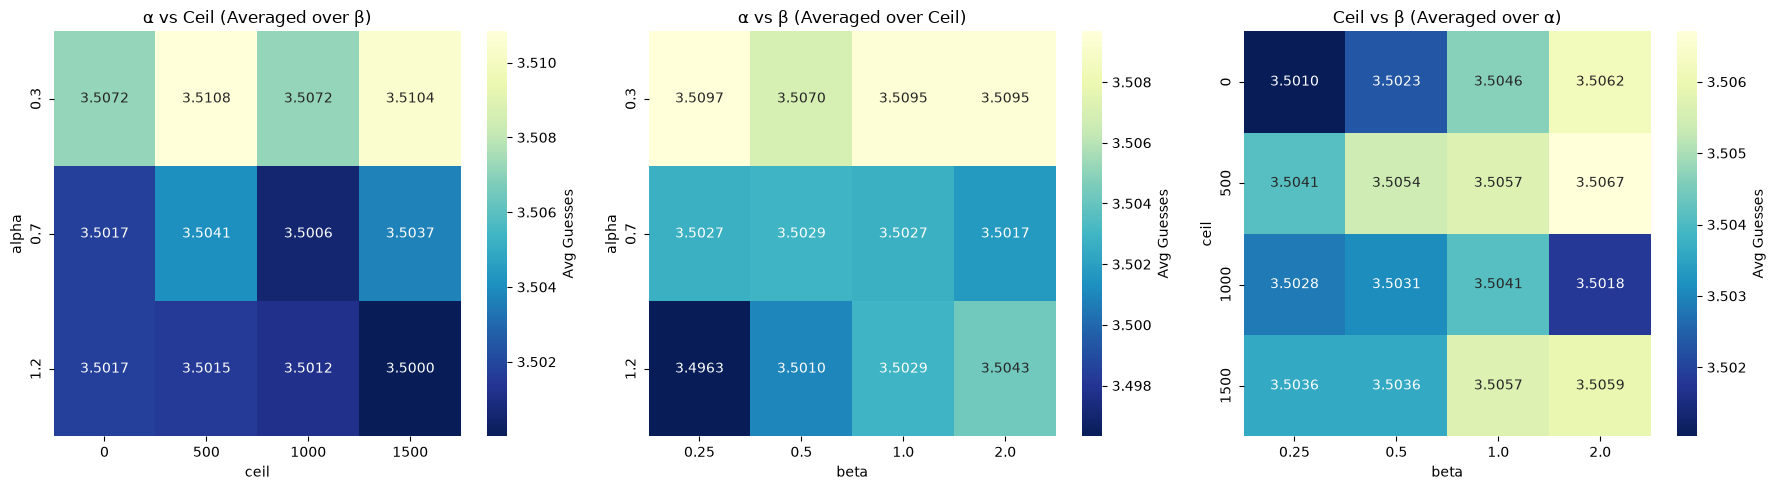

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load grid search output
df_res = pd.read_csv('../data/grid_search_results_new.csv')

# Exclude baseline (alpha=0) for continuous heatmap visualization
df_sweep = df_res[df_res['alpha'] > 0].copy()

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Alpha vs Ceil
p1 = df_sweep.pivot_table(index='alpha', columns='ceil', values='overall_avg', aggfunc='mean')
sns.heatmap(p1, annot=True, fmt=".4f", cmap="YlGnBu_r", ax=axes[0], cbar_kws={'label': 'Avg Guesses'})
axes[0].set_title('α vs Ceil (Averaged over β)')

# 2. Alpha vs Beta
p2 = df_sweep.pivot_table(index='alpha', columns='beta', values='overall_avg', aggfunc='mean')
sns.heatmap(p2, annot=True, fmt=".4f", cmap="YlGnBu_r", ax=axes[1], cbar_kws={'label': 'Avg Guesses'})
axes[1].set_title('α vs β (Averaged over Ceil)')

# 3. Ceil vs Beta
p3 = df_sweep.pivot_table(index='ceil', columns='beta', values='overall_avg', aggfunc='mean')
sns.heatmap(p3, annot=True, fmt=".4f", cmap="YlGnBu_r", ax=axes[2], cbar_kws={'label': 'Avg Guesses'})
axes[2].set_title('Ceil vs β (Averaged over α)')

plt.tight_layout()
plt.show()

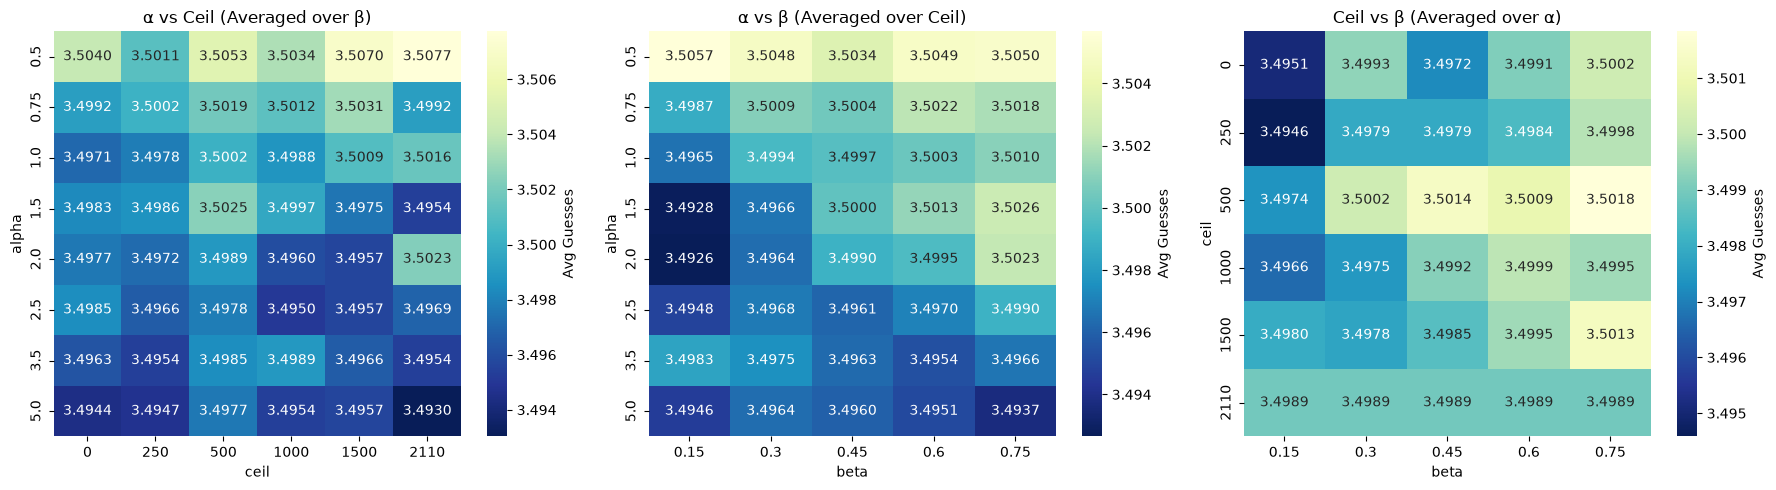

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load grid search output
df_res = pd.read_csv('../data/grid_search_results_new_2.csv')

# Exclude baseline (alpha=0) for continuous heatmap visualization
df_sweep = df_res[df_res['alpha'] > 0].copy()

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Alpha vs Ceil
p1 = df_sweep.pivot_table(index='alpha', columns='ceil', values='overall_avg', aggfunc='mean')
sns.heatmap(p1, annot=True, fmt=".4f", cmap="YlGnBu_r", ax=axes[0], cbar_kws={'label': 'Avg Guesses'})
axes[0].set_title('α vs Ceil (Averaged over β)')

# 2. Alpha vs Beta
p2 = df_sweep.pivot_table(index='alpha', columns='beta', values='overall_avg', aggfunc='mean')
sns.heatmap(p2, annot=True, fmt=".4f", cmap="YlGnBu_r", ax=axes[1], cbar_kws={'label': 'Avg Guesses'})
axes[1].set_title('α vs β (Averaged over Ceil)')

# 3. Ceil vs Beta
p3 = df_sweep.pivot_table(index='ceil', columns='beta', values='overall_avg', aggfunc='mean')
sns.heatmap(p3, annot=True, fmt=".4f", cmap="YlGnBu_r", ax=axes[2], cbar_kws={'label': 'Avg Guesses'})
axes[2].set_title('Ceil vs β (Averaged over α)')

plt.tight_layout()
plt.show()

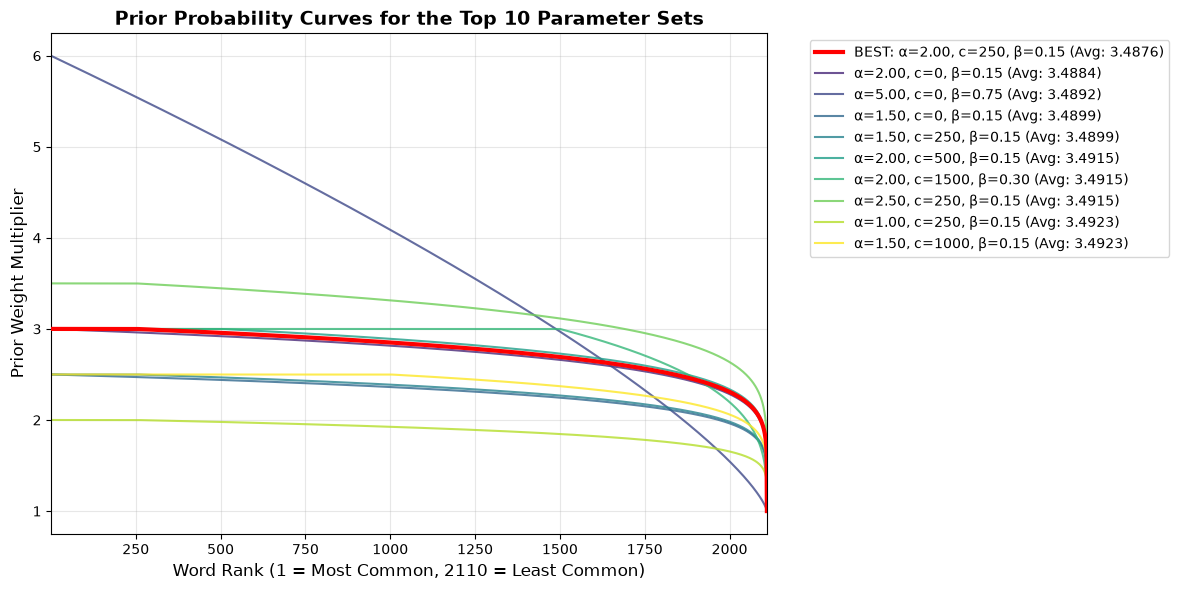

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Load data
df_res = pd.read_csv('../data/grid_search_results_new_2.csv')

# 2. Get the top 10 individual parameter combinations overall
top_10 = df_res.nsmallest(10, 'overall_avg')

# 3. Function to mathematically generate the curve
def generate_curve(alpha, ceil, beta, n_top=2110):
    ranks = np.arange(1, n_top + 1)
    priors = np.ones(n_top)
    
    # Ceiling region
    ceil = int(min(ceil, n_top))
    priors[:ceil] = 1.0 + alpha
    
    # Tail decay region
    if ceil < n_top:
        tail_ranks = ranks[ceil:]
        norm_tail_pos = (n_top - tail_ranks) / (n_top - ceil)
        priors[ceil:] = 1.0 + alpha * (norm_tail_pos ** beta)
        
    return ranks, priors

# 4. Plot the curves
plt.figure(figsize=(12, 6))

colors = plt.cm.viridis(np.linspace(0, 1, 10))
for idx, (i, row) in enumerate(top_10.iterrows()):
    r, p = generate_curve(row['alpha'], row['ceil'], row['beta'])
    label_str = f"α={row['alpha']:.2f}, c={int(row['ceil'])}, β={row['beta']:.2f} (Avg: {row['overall_avg']:.4f})"
    
    # Highlight the absolute best run in red and slightly thicker
    if idx == 0:
        plt.plot(r, p, color='red', linewidth=3, zorder=10, label=f"BEST: {label_str}")
    else:
        plt.plot(r, p, color=colors[idx], linewidth=1.5, alpha=0.8, label=label_str)

plt.title('Prior Probability Curves for the Top 10 Parameter Sets', fontsize=14, fontweight='bold')
plt.xlabel('Word Rank (1 = Most Common, 2110 = Least Common)', fontsize=12)
plt.ylabel('Prior Weight Multiplier', fontsize=12)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, alpha=0.3)
plt.xlim(1, 2110)
plt.tight_layout()
plt.show()

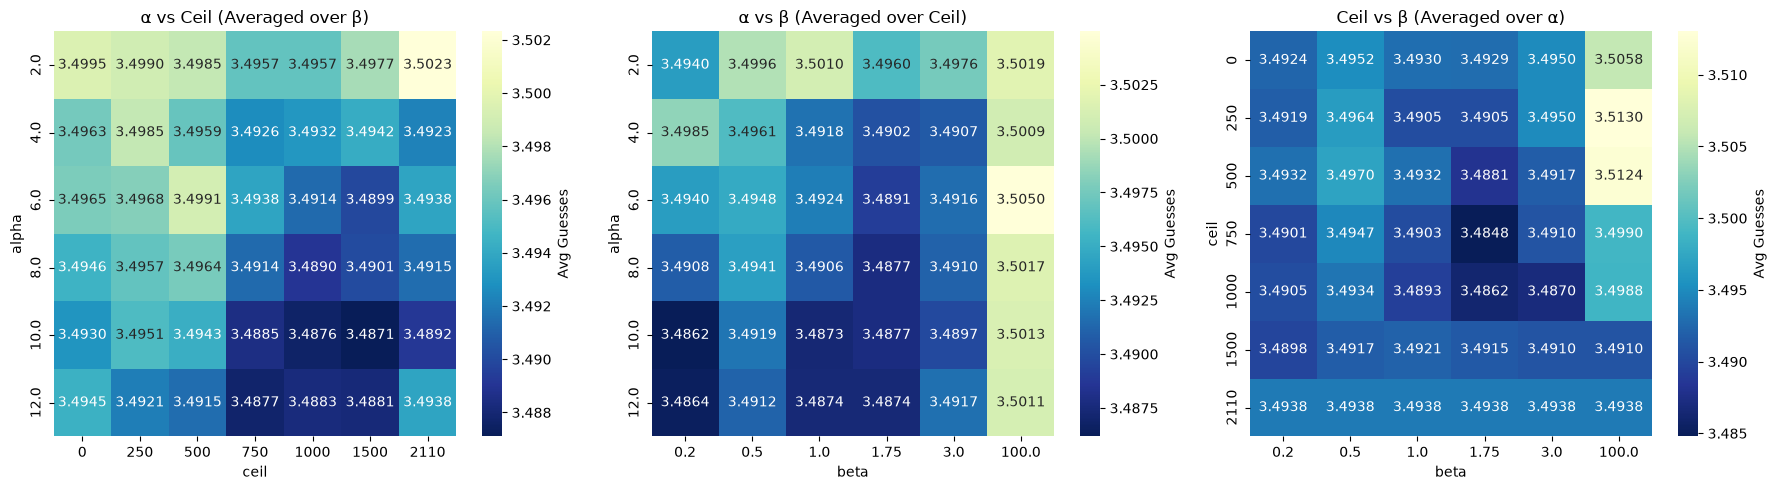

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load grid search output
df_res = pd.read_csv('../data/grid_search_results_new_3.csv')

# Exclude baseline (alpha=0) for continuous heatmap visualization
df_sweep = df_res[df_res['alpha'] > 0].copy()

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Alpha vs Ceil
p1 = df_sweep.pivot_table(index='alpha', columns='ceil', values='overall_avg', aggfunc='mean')
sns.heatmap(p1, annot=True, fmt=".4f", cmap="YlGnBu_r", ax=axes[0], cbar_kws={'label': 'Avg Guesses'})
axes[0].set_title('α vs Ceil (Averaged over β)')

# 2. Alpha vs Beta
p2 = df_sweep.pivot_table(index='alpha', columns='beta', values='overall_avg', aggfunc='mean')
sns.heatmap(p2, annot=True, fmt=".4f", cmap="YlGnBu_r", ax=axes[1], cbar_kws={'label': 'Avg Guesses'})
axes[1].set_title('α vs β (Averaged over Ceil)')

# 3. Ceil vs Beta
p3 = df_sweep.pivot_table(index='ceil', columns='beta', values='overall_avg', aggfunc='mean')
sns.heatmap(p3, annot=True, fmt=".4f", cmap="YlGnBu_r", ax=axes[2], cbar_kws={'label': 'Avg Guesses'})
axes[2].set_title('Ceil vs β (Averaged over α)')

plt.tight_layout()
plt.show()

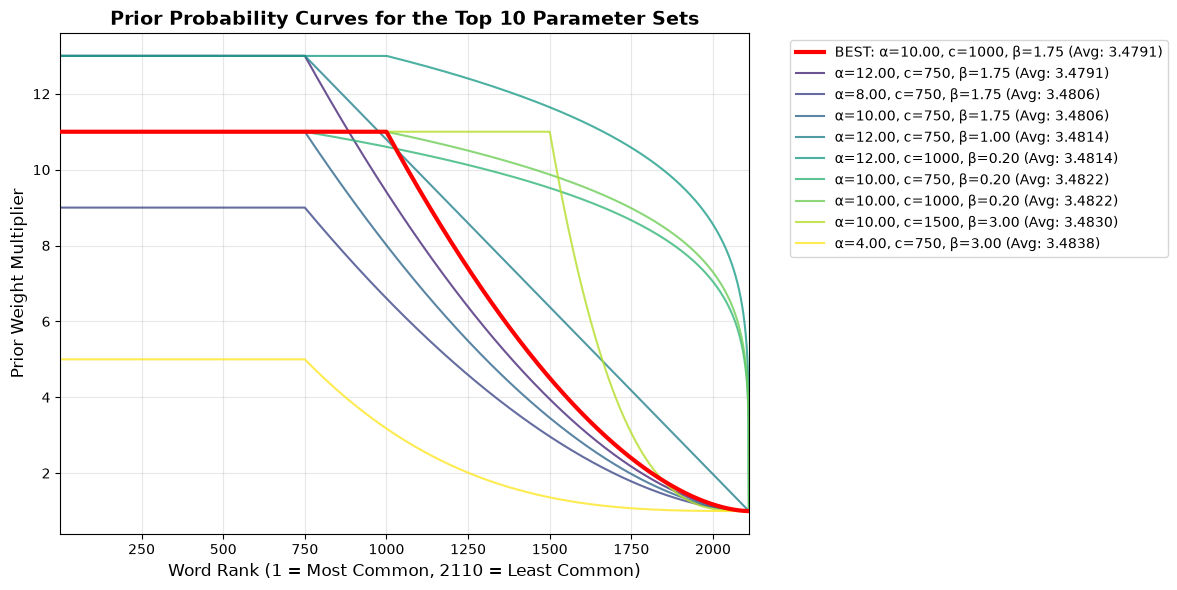

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Load data
df_res = pd.read_csv('../data/grid_search_results_new_3.csv')

# 2. Get the top 10 individual parameter combinations overall
top_10 = df_res.nsmallest(10, 'overall_avg')

# 3. Function to mathematically generate the curve
def generate_curve(alpha, ceil, beta, n_top=2110):
    ranks = np.arange(1, n_top + 1)
    priors = np.ones(n_top)
    
    # Ceiling region
    ceil = int(min(ceil, n_top))
    priors[:ceil] = 1.0 + alpha
    
    # Tail decay region
    if ceil < n_top:
        tail_ranks = ranks[ceil:]
        norm_tail_pos = (n_top - tail_ranks) / (n_top - ceil)
        priors[ceil:] = 1.0 + alpha * (norm_tail_pos ** beta)
        
    return ranks, priors

# 4. Plot the curves
plt.figure(figsize=(12, 6))

colors = plt.cm.viridis(np.linspace(0, 1, 10))
for idx, (i, row) in enumerate(top_10.iterrows()):
    r, p = generate_curve(row['alpha'], row['ceil'], row['beta'])
    label_str = f"α={row['alpha']:.2f}, c={int(row['ceil'])}, β={row['beta']:.2f} (Avg: {row['overall_avg']:.4f})"
    
    # Highlight the absolute best run in red and slightly thicker
    if idx == 0:
        plt.plot(r, p, color='red', linewidth=3, zorder=10, label=f"BEST: {label_str}")
    else:
        plt.plot(r, p, color=colors[idx], linewidth=1.5, alpha=0.8, label=label_str)

plt.title('Prior Probability Curves for the Top 10 Parameter Sets', fontsize=14, fontweight='bold')
plt.xlabel('Word Rank (1 = Most Common, 2110 = Least Common)', fontsize=12)
plt.ylabel('Prior Weight Multiplier', fontsize=12)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, alpha=0.3)
plt.xlim(1, 2110)
plt.tight_layout()
plt.show()

In [6]:
import numpy as np
import pandas as pd

# Parameters
ALPHA = 4.0
CEIL = 750
BETA = 3.0

# Retain the existing low-prior floor as a separate operation.
FLOOR_THRESHOLD = 0.004
FLOOR_REPLACEMENT = 0.0001

input_priors_path = "../data/priors_4500.csv"
rankings_path = "../data/full_frequency_heuristics.csv"
output_priors_path = "../data/priors_reweighted.csv"

# Load priors, whether the CSV has a header or not.
raw_priors = pd.read_csv(input_priors_path, header=None)
try:
    float(raw_priors.iloc[0, 1])
    df_priors = raw_priors.iloc[:, :2].copy()
    df_priors.columns = ["word", "prior"]
except (ValueError, TypeError):
    df_priors = pd.read_csv(input_priors_path).iloc[:, :2].copy()
    df_priors.columns = ["word", "prior"]

df_priors["word"] = df_priors["word"].astype(str).str.strip().str.lower()
df_priors["prior"] = pd.to_numeric(
    df_priors["prior"], errors="coerce"
).fillna(0.0)

if df_priors["word"].duplicated().any():
    raise ValueError("Duplicate words found in the priors file.")

# Load the heuristic frequency ranks (rank 1 = most frequent).
heuristics = pd.read_csv(rankings_path)
required_columns = {"word", "stage_1_rank"}
if not required_columns.issubset(heuristics.columns):
    raise ValueError(
        f"{rankings_path} must contain 'word' and 'stage_1_rank' columns."
    )

heuristics["word"] = heuristics["word"].astype(str).str.strip().str.lower()
heuristics["stage_1_rank"] = pd.to_numeric(
    heuristics["stage_1_rank"], errors="coerce"
)
heuristics = heuristics.dropna(subset=["stage_1_rank"])

if heuristics["word"].duplicated().any():
    raise ValueError("Duplicate words found in the frequency-rank file.")

rank_by_word = heuristics.set_index("word")["stage_1_rank"]

# Apply the reweighting curve to prior-1 words ordered by frequency rank.
s_priors = df_priors["prior"].copy()
top_positions = np.flatnonzero(
    np.isclose(s_priors.to_numpy(dtype=float), 1.0)
)
n_top = len(top_positions)

if n_top:
    top_words = df_priors.iloc[top_positions]["word"]
    top_ranks = top_words.map(rank_by_word)

    if top_ranks.isna().any():
        missing = top_words[top_ranks.isna()].tolist()
        raise ValueError(
            f"{len(missing)} prior-1 words lack stage_1_rank; "
            f"examples: {missing[:10]}"
        )

    # Stable sort: frequency rank 1 receives the first curve weight.
    order = np.argsort(top_ranks.to_numpy(dtype=float), kind="stable")
    ordered_positions = top_positions[order]

    effective_ceil = min(CEIL, n_top)
    ranks = np.arange(1, n_top + 1)
    top_priors = np.empty(n_top, dtype=float)

    top_priors[:effective_ceil] = 1.0 + ALPHA

    if effective_ceil < n_top:
        tail_ranks = ranks[effective_ceil:]
        normalized_tail = (n_top - tail_ranks) / (n_top - effective_ceil)
        top_priors[effective_ceil:] = (
            1.0 + ALPHA * normalized_tail**BETA
        )

    s_priors.iloc[ordered_positions] = top_priors

# Apply the existing floor separately from the frequency-based reweighting.
floored_mask = s_priors < FLOOR_THRESHOLD
s_priors.iloc[np.flatnonzero(floored_mask.to_numpy())] = FLOOR_REPLACEMENT

df_priors["prior"] = s_priors
df_priors.to_csv(output_priors_path, index=False)

print(f"Reweighted {n_top:,} prior-1 words by stage_1_rank.")
print(f"Maximum reweighted prior: {s_priors.max():.6f}")
print(
    f"Floored {int(floored_mask.sum()):,} priors below "
    f"{FLOOR_THRESHOLD} to {FLOOR_REPLACEMENT}."
)
print(f"Saved reweighted priors to: {output_priors_path}")

Reweighted 2,110 prior-1 words by stage_1_rank.
Maximum reweighted prior: 5.000000
Floored 1,518 priors below 0.004 to 0.0001.
Saved reweighted priors to: ../data/priors_reweighted.csv
